# Modeling notebook
In this part I will split the data, impute the missing values, do some feature engineering and deploy a baseline model and then some more advanced model.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor

DATA_PATH = Path("..") / "opsd-time_series-2020-10-06"

In [2]:
# loading the dataset with the weather, seting the datetime index and keeping only the czech load and temperature
raw_df = pd.read_csv(DATA_PATH / "load_with_weather.csv")

czech_load = raw_df[["cet_cest_timestamp",
                     "CZ_load_actual_entsoe_transparency",
                     "CZ_temperature"]]

czech_load.index = (pd.to_datetime(czech_load["cet_cest_timestamp"], utc=True).dt.tz_convert("Europe/Prague"))

czech_load = czech_load.drop("cet_cest_timestamp", axis=1)

# the weather data are missing for 2020 so I drop the whole year
czech_load = czech_load[czech_load.index.year != 2020]

czech_load.head()

,CZ_load_actual_entsoe_transparency,CZ_temperature
cet_cest_timestamp,,
2015-01-01 00:00:00+01:00,NaN,-2.604
2015-01-01 01:00:00+01:00,NaN,-2.372
2015-01-01 02:00:00+01:00,5957.57,-2.126
2015-01-01 03:00:00+01:00,5878.87,-1.839
2015-01-01 04:00:00+01:00,5827.80,-1.521


In [3]:
# I'll create a column that will flag if the load was missing and rename the original variables
czech_load = czech_load.rename(columns = {'CZ_load_actual_entsoe_transparency' : 'actual_load',
                                          'CZ_temperature' : 'temperature'})
czech_load['was_missing'] = czech_load['actual_load'].isna()

In [4]:
# splittin the data into train, val and test sets and checking the sizes if the split went well
train = czech_load[czech_load.index.year <= 2017]
val = czech_load[czech_load.index.year == 2018]
test = czech_load[czech_load.index.year == 2019]

print(f"Length of train: {len(train)}, val: {len(val)}, test: {len(test)}.")

Length of train: 26304, val: 8760, test: 8760.


I will impute the missing values based on seasonal average from the same day of the week and hour. It's not a very good imputation since it's missing the information about what part of the year it is, but it will do. I will also use it as a very simple baseline prediction.

In [5]:
# now I will impute the missing values based on the train set values to prevent data leakage
# I'm also creating the was_missing flag, so I don't loose the information which values were missing and so I don't evaluate the models on these rows
# And I will also keep the seasonal_avg column which will serve as the baseline prediction
impute_df = train.groupby([train.index.day_of_week, train.index.hour])[['actual_load', 'was_missing']].mean().reset_index(names=['day_of_week', 'hour'])
impute_df = impute_df.set_index(['day_of_week', 'hour'])
impute_df = impute_df.rename(columns = {'actual_load' : 'seasonal_avg'})
impute_df = impute_df.drop(['was_missing'], axis = 1)

def impute_missing(df, imp_df):
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.day_of_week
    df = df.join(imp_df, on = ['day_of_week', 'hour'])
    df = df.drop(['hour', 'day_of_week'], axis = 1)
    df['actual_load'] = df['actual_load'].fillna(df['seasonal_avg'])
    return df

train = impute_missing(train, impute_df)
val = impute_missing(val, impute_df)
test = impute_missing(test, impute_df)


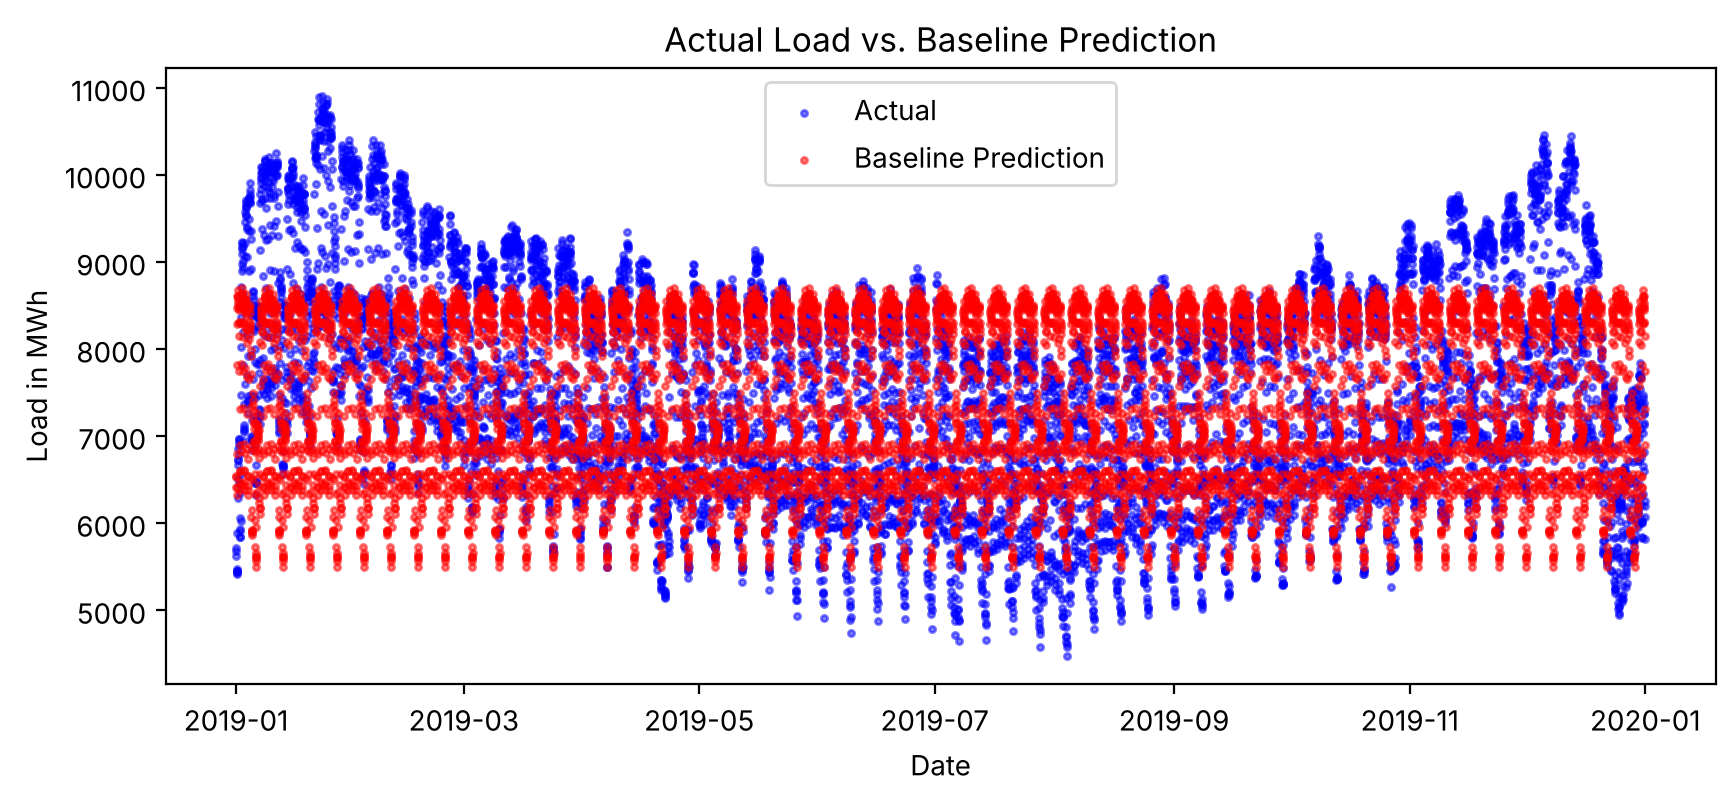

In [6]:
# plotting the baseline on the test set
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(test.index, test['actual_load'], label = 'Actual', color = 'blue', alpha = 0.5, s = 5)
ax.scatter(test.index, test['seasonal_avg'], label = 'Baseline Prediction', color = 'red', alpha = 0.5, s = 5)
ax.set_title('Actual Load vs. Baseline Prediction')
ax.set_ylabel('Load in MWh')
ax.set_xlabel('Date')
ax.legend()
plt.show()

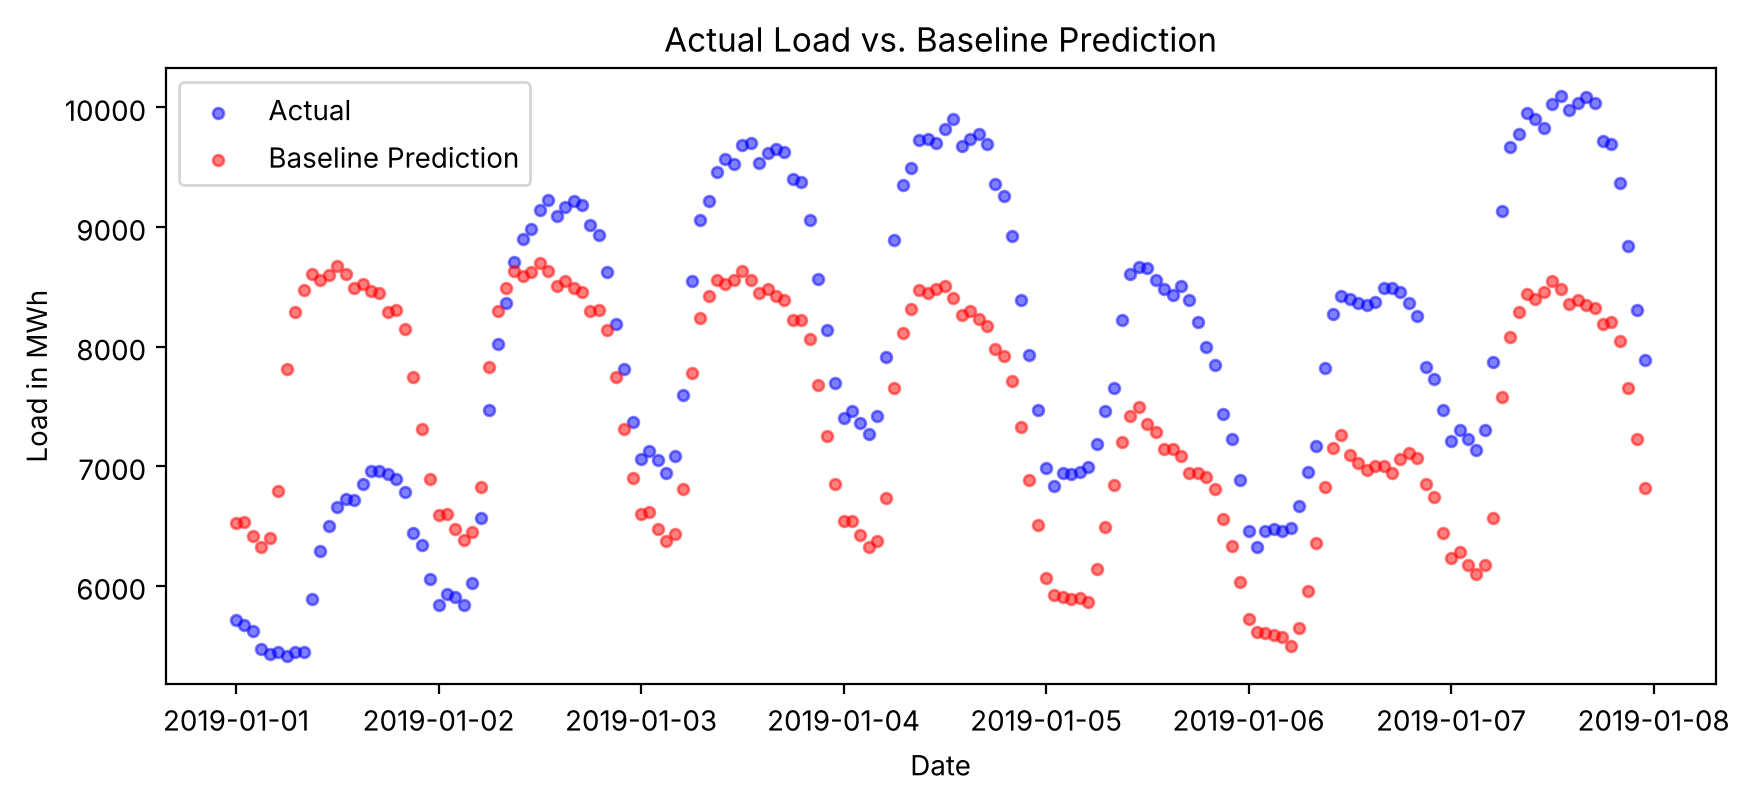

In [7]:
# same plot but only for one week
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(test[:168].index, test['actual_load'][:168], label = 'Actual', color = 'blue', alpha = 0.5, s = 15)
ax.scatter(test[:168].index, test['seasonal_avg'][:168], label = 'Baseline Prediction', color = 'red', alpha = 0.5, s = 15)
ax.set_title('Actual Load vs. Baseline Prediction')
ax.set_ylabel('Load in MWh')
ax.set_xlabel('Date')
ax.legend()
plt.show()

We can see that the baseline prediction prediction coppies the weekly and hourly pattern well (lower load on weekends, lower load at night), but doesn't capture the seasonality during a year (higher load in winter, lowest load in summer).

### Feature engineering
Now I'll do some feature engineering. That I will use for a random forest model.

In [8]:
# creating the function that will implement the features
# I'm creating features that will work for a one day ahead prediction (at midnight it will be possible to predict the whole upcomming day)
def create_features(df):
    df['is_weekend'] = ((df.index.day_of_week == 5) | (df.index.day_of_week == 6)).astype(int)
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.day_of_week
    df['month'] = df.index.month
    
    df['lag_24'] = df['actual_load'].shift(24)
    df['lag_48'] = df['actual_load'].shift(48)
    df['lag_168'] = df['actual_load'].shift(168)
    
    df['temp_lag_24'] = df['temperature'].shift(24)
    df['temp_lag_48'] = df['temperature'].shift(48)
    df['temp_lag_168'] = df['temperature'].shift(168)
    
    # here every hour in a day will have a daily average of the previous day
    daily_prev_mean = df['actual_load'].resample('D').mean().shift(1)
    df['prev_day_mean'] = df.index.normalize().map(daily_prev_mean)
    
    daily_prev_mean = df['temperature'].resample('D').mean().shift(1)
    df['prev_day_mean_temp'] = df.index.normalize().map(daily_prev_mean)
    
    # encoding hour, day of week and day of year using cos sin encoding so the model knows that it's cycle
    df['hour_sin'] = np.sin(2 * np.pi * df.index.hour / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * df.index.hour / 24.0)
    
    df['dow_sin'] = np.sin(2 * np.pi * df.index.day_of_week / 7.0)
    df['dow_cos'] = np.cos(2 * np.pi * df.index.day_of_week / 7.0)
    
    df['doy_sin'] = np.sin(2 * np.pi * df.index.day_of_year / 365)
    df['doy_cos'] = np.cos(2 * np.pi * df.index.day_of_year / 365)
    
    return df
    
# keeping the not imputed data, because for the final model I will do the imputation again on train + val
czech_load_raw = czech_load.copy()

czech_load = impute_missing(czech_load, impute_df)    
czech_load_w_features = create_features(czech_load)

### Random forest model
I'll split the data with features the same way as before (train 2015–2017, val 2018, test 2019). The model is trained only on rows where the load was actually measured, not imputed, and both models are evaluated only on non-imputed rows.

In [9]:
# features available at midnight for a one day ahead prediction
features = ['is_weekend', 'hour', 'day_of_week', 'month',
            'lag_24', 'lag_48', 'lag_168', 'prev_day_mean',
            'temp_lag_24', 'temp_lag_48', 'temp_lag_168', 'prev_day_mean_temp',
            'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos']
target = 'actual_load'

# the first week of 2015 has no lag_168, so I drop rows with missing features
train_f = czech_load_w_features[czech_load_w_features.index.year <= 2017].dropna(subset=features).copy()
val_f = czech_load_w_features[czech_load_w_features.index.year == 2018].copy()

# training only on real measurements, not on imputed values
train_fit = train_f[~train_f['was_missing']]

print(f"Train rows used for fitting: {len(train_fit)}, val: {len(val_f)}.")

Train rows used for fitting: 26029, val: 8760.


In [10]:
# fitting 9 random forests with different hyperparameters, same as for the solar
rf_params = {
    'RF 1': dict(max_features=1.0, min_samples_leaf=1),
    'RF 2': dict(max_features=0.5, min_samples_leaf=1),
    'RF 3': dict(max_features='sqrt', min_samples_leaf=1),
    'RF 4': dict(max_features=1.0, min_samples_leaf=5),
    'RF 5': dict(max_features=0.5, min_samples_leaf=5),
    'RF 6': dict(max_features='sqrt', min_samples_leaf=5),
    'RF 7': dict(max_features=1.0, min_samples_leaf=20),
    'RF 8': dict(max_features=0.5, min_samples_leaf=20),
    'RF 9': dict(max_features='sqrt', min_samples_leaf=20)
}

rf_models = {}
for name, params in rf_params.items():
    model = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **params)
    model.fit(train_fit[features], train_fit[target])
    rf_models[name] = model
    val_f[name] = model.predict(val_f[features])
    print(f"{name} fitted")

RF 1 fitted


RF 2 fitted


RF 3 fitted


RF 4 fitted


RF 5 fitted


RF 6 fitted


RF 7 fitted


RF 8 fitted


RF 9 fitted


### Evaluation
I compare the baseline (seasonal average by day of week and hour) with the random forest using MAE, RMSE and MAPE. Rows where the load was imputed are left out, because there is no real value to compare against.

In [11]:
def evaluate(df, pred_col):
    df = df[~df['was_missing']]
    err = df['actual_load'] - df[pred_col]
    return {'MAE': err.abs().mean(),
            'RMSE': np.sqrt((err ** 2).mean()),
            'MAPE (%)': (err.abs() / df['actual_load']).mean() * 100}

# comparing the baseline and all the models on the validation set
val_results = pd.DataFrame({name: evaluate(val_f, name)
                            for name in ['seasonal_avg', *rf_models]}).T
val_results.round(2)

,MAE,RMSE,MAPE (%)
seasonal_avg,693.73,882.91,8.88
RF 1,173.97,284.33,2.28
RF 2,162.13,258.82,2.12
RF 3,167.36,262.50,2.16
RF 4,176.30,290.18,2.31
RF 5,164.78,264.47,2.16
RF 6,171.57,266.21,2.23
RF 7,186.33,306.53,2.45
RF 8,177.15,280.10,2.32
RF 9,185.40,286.07,2.41


In [12]:
# choosing the random forest with the lowest validation MAE
best_name = val_results.loc[list(rf_models), 'MAE'].idxmin()
print(f"Best model on validation: {best_name} {rf_params[best_name]}")

Best model on validation: RF 2 {'max_features': 0.5, 'min_samples_leaf': 1}


In [13]:
# for the final model I use train + val, so I compute the seasonal average again on 2015-2018
# it's used for the imputation and also as the baseline, so the baseline gets the same data as the model
train_val = czech_load_raw[czech_load_raw.index.year <= 2018]

impute_df_tv = train_val.groupby([train_val.index.day_of_week, train_val.index.hour])[['actual_load', 'was_missing']].mean().reset_index(names=['day_of_week', 'hour'])
impute_df_tv = impute_df_tv.set_index(['day_of_week', 'hour'])
impute_df_tv = impute_df_tv.rename(columns = {'actual_load' : 'seasonal_avg'})
impute_df_tv = impute_df_tv.drop(['was_missing'], axis = 1)

czech_load_tv = impute_missing(czech_load_raw.copy(), impute_df_tv)
czech_load_tv = create_features(czech_load_tv)

train_val_f = czech_load_tv[czech_load_tv.index.year <= 2018].dropna(subset=features)
train_val_fit = train_val_f[~train_val_f['was_missing']]
test_f = czech_load_tv[czech_load_tv.index.year == 2019].copy()

# training the best hyperparameters on train + val and testing it
final_rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **rf_params[best_name])
final_rf.fit(train_val_fit[features], train_val_fit[target])
test_f['rf_pred'] = final_rf.predict(test_f[features])

test_results = pd.DataFrame({
    'Baseline': evaluate(test_f, 'seasonal_avg'),
    f'Random forest ({best_name})': evaluate(test_f, 'rf_pred'),
}).T.round(2)
test_results

,MAE,RMSE,MAPE (%)
Baseline,630.96,790.42,8.37
Random forest (RF 2),165.01,262.43,2.20


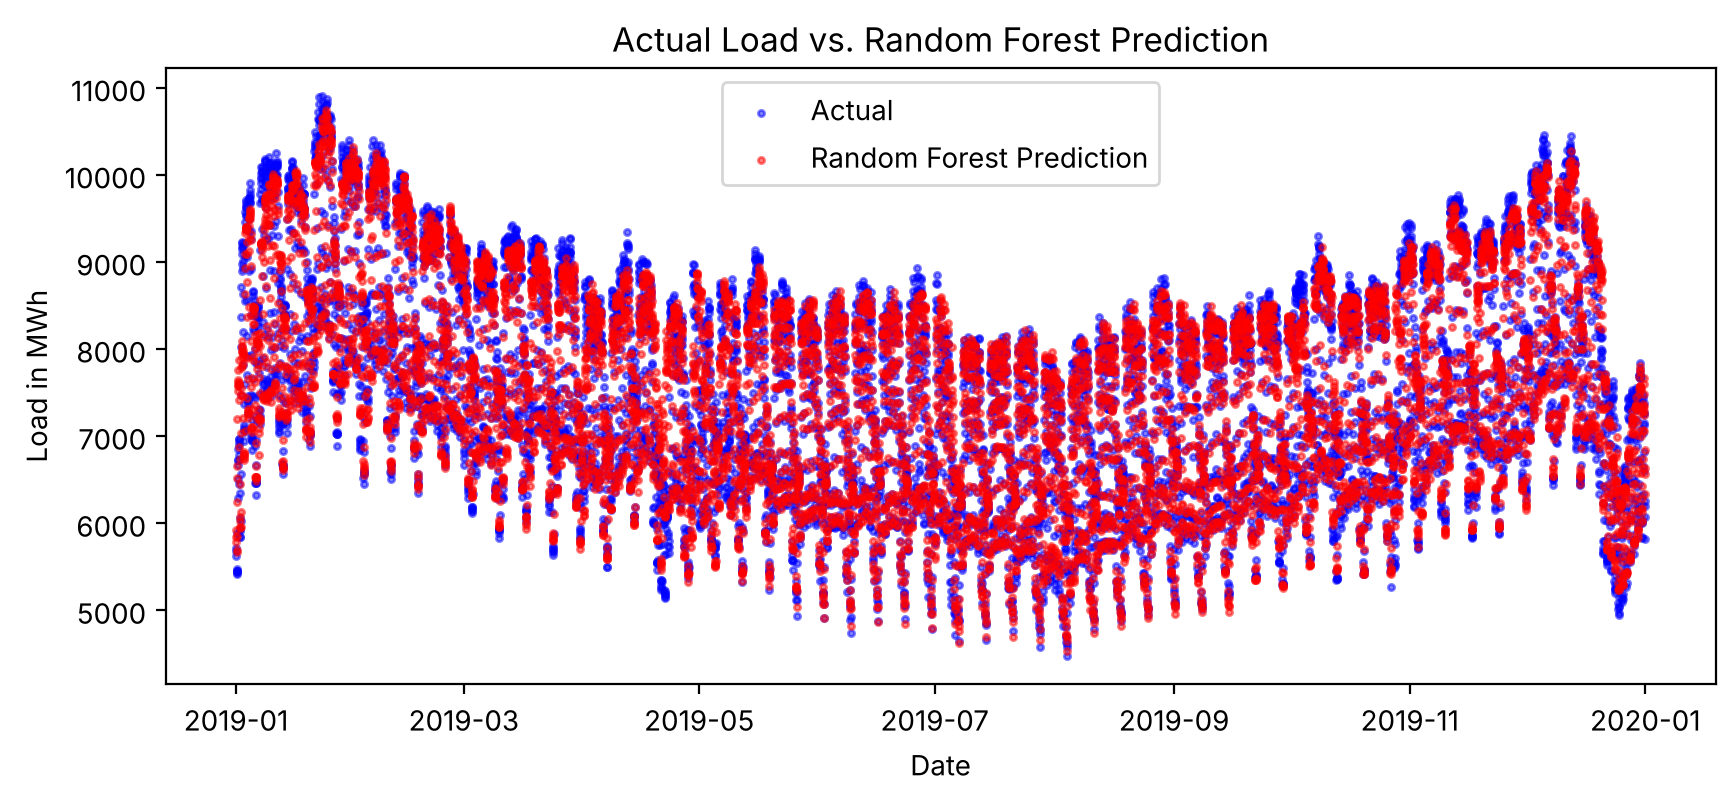

In [14]:
# plotting the random forest on the test set
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(test_f.index, test_f['actual_load'], label = 'Actual', color = 'blue', alpha = 0.5, s = 5)
ax.scatter(test_f.index, test_f['rf_pred'], label = 'Random Forest Prediction', color = 'red', alpha = 0.5, s = 5)
ax.set_title('Actual Load vs. Random Forest Prediction')
ax.set_ylabel('Load in MWh')
ax.set_xlabel('Date')
ax.legend()
plt.show()

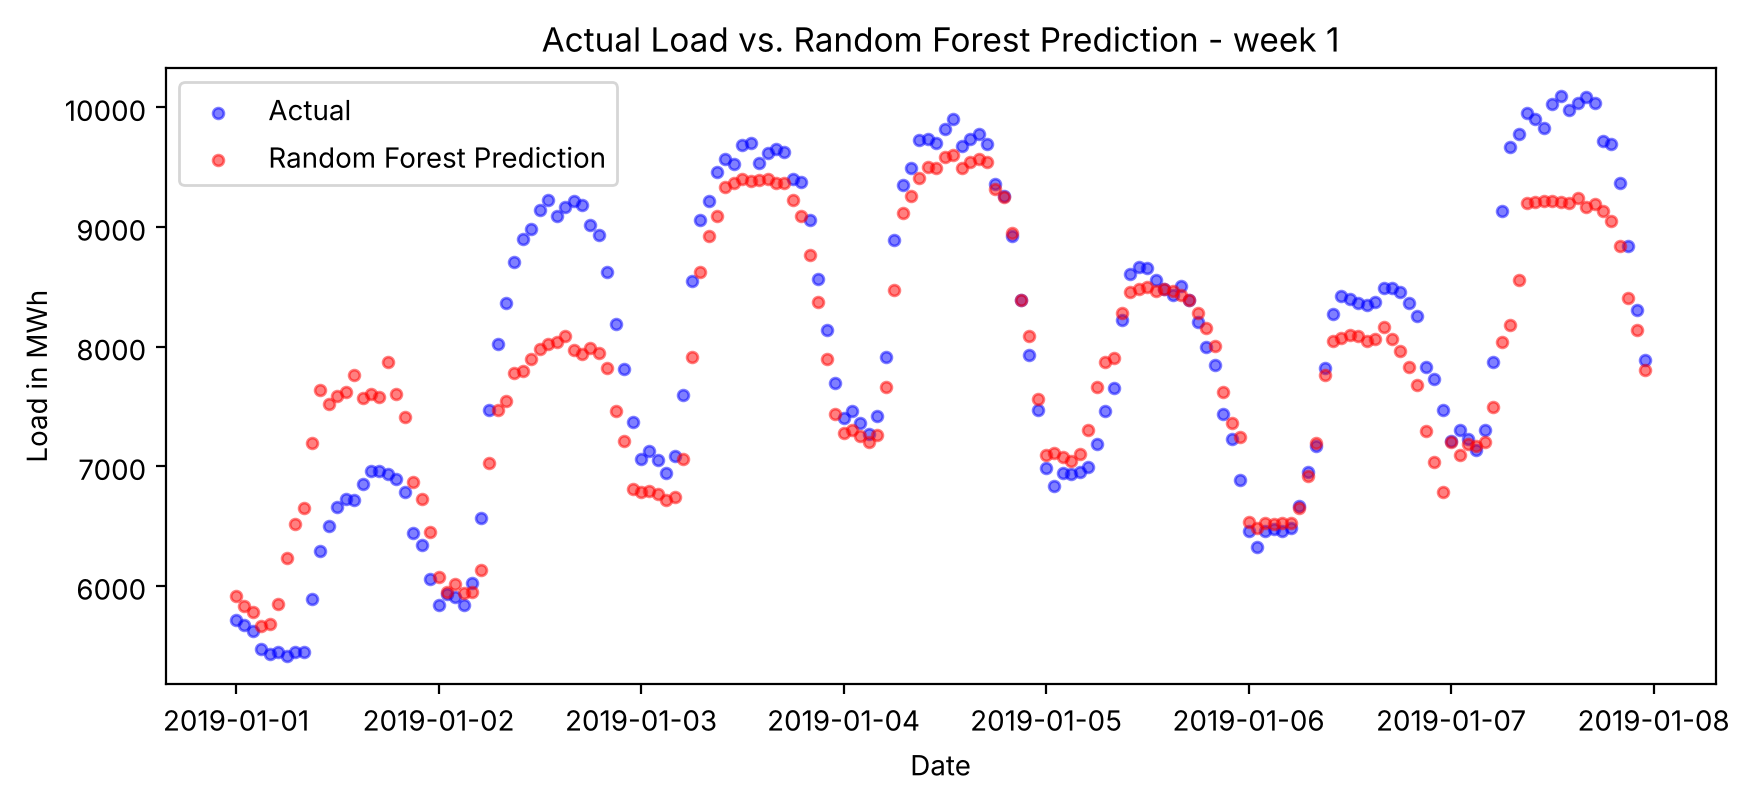

In [15]:
# same plot but only for one week
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(test_f[:168].index, test_f['actual_load'][:168], label = 'Actual', color = 'blue', alpha = 0.5, s = 15)
ax.scatter(test_f[:168].index, test_f['rf_pred'][:168], label = 'Random Forest Prediction', color = 'red', alpha = 0.5, s = 15)
ax.set_title('Actual Load vs. Random Forest Prediction - week 1')
ax.set_ylabel('Load in MWh')
ax.set_xlabel('Date')
ax.legend()
plt.show()

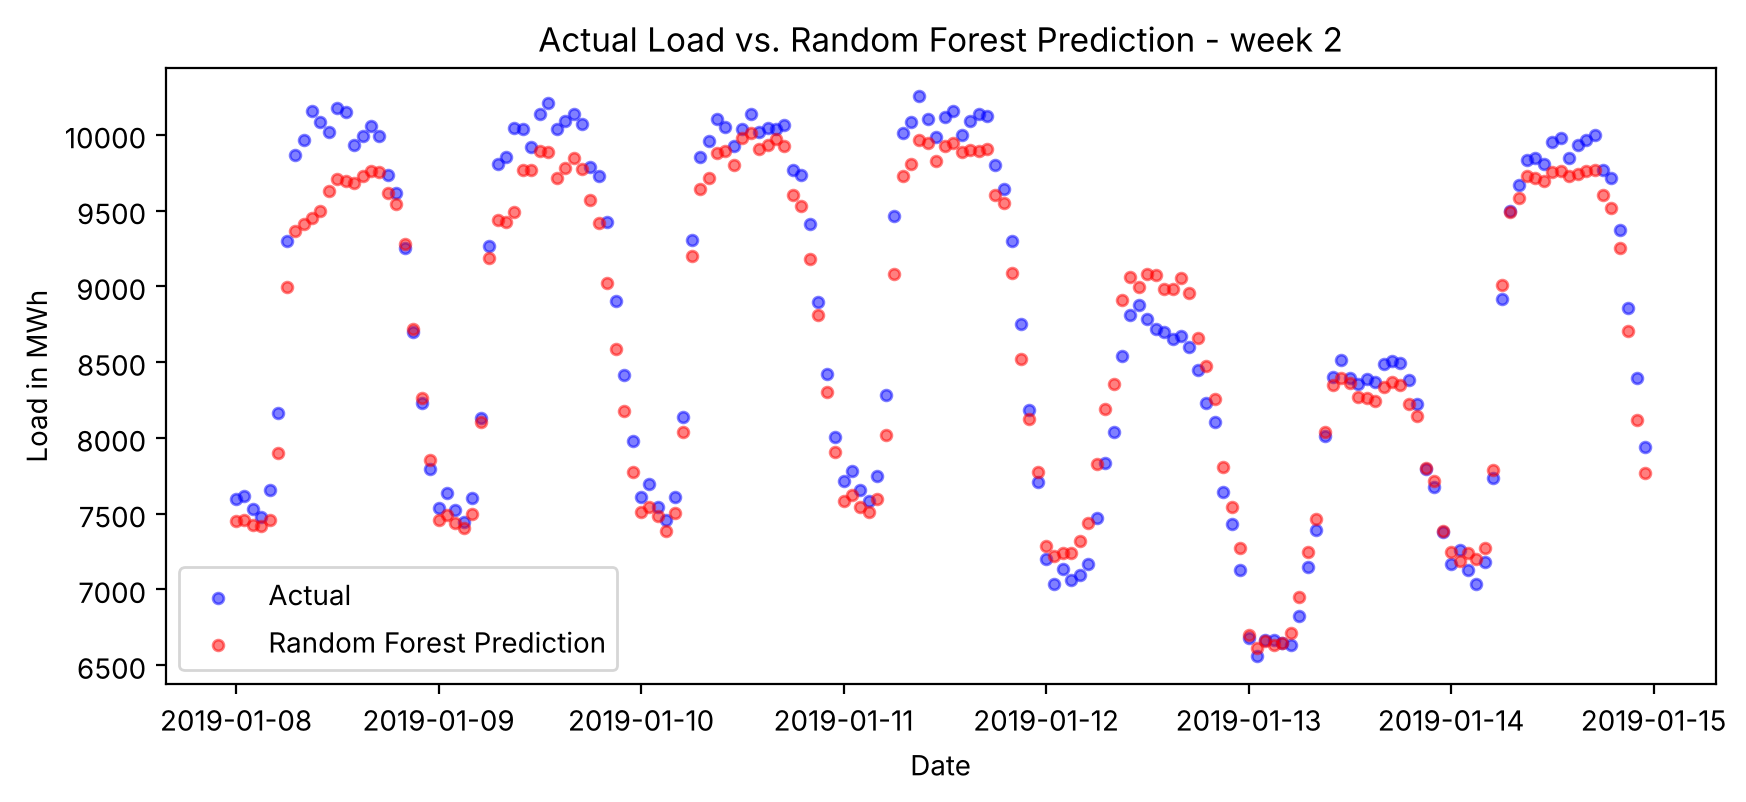

In [16]:
# and a one more week
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(test_f[168:336].index, test_f['actual_load'][168:336], label = 'Actual', color = 'blue', alpha = 0.5, s = 15)
ax.scatter(test_f[168:336].index, test_f['rf_pred'][168:336], label = 'Random Forest Prediction', color = 'red', alpha = 0.5, s = 15)
ax.set_title('Actual Load vs. Random Forest Prediction - week 2')
ax.set_ylabel('Load in MWh')
ax.set_xlabel('Date')
ax.legend()
plt.show()

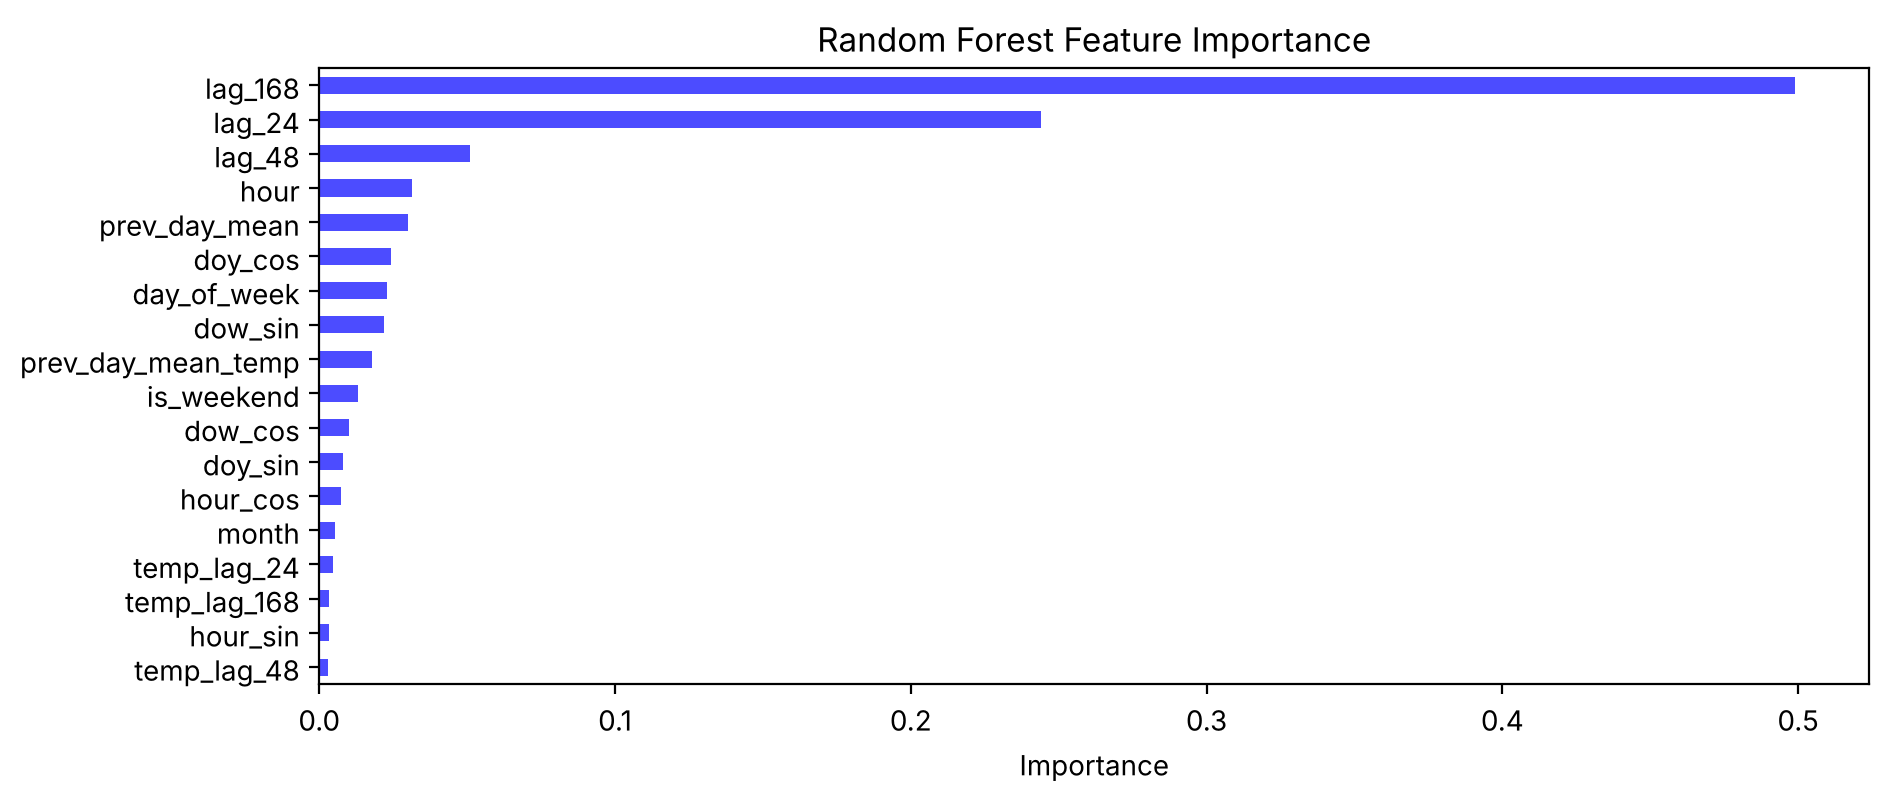

In [17]:
# most important predictors of the random forest
importances = pd.Series(final_rf.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize = (10, 4))
importances.sort_values().plot.barh(ax = ax, color = 'blue', alpha = 0.7)
ax.set_title('Random Forest Feature Importance')
ax.set_xlabel('Importance')
plt.show()